# redback shock cooling with lightcurvelynx

_Shar Daniels (UD), Alex Malz (STScI)_

## setup

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats as sps

from redback import model_library
from redback.priors import get_priors
import redback
from lightcurvelynx.astro_utils.passbands import PassbandGroup
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.math_nodes.scipy_random import ScipyRandomDist
from lightcurvelynx.math_nodes.ra_dec_sampler import ObsTableRADECSampler
from lightcurvelynx.obstable.opsim import OpSim
from lightcurvelynx.simulate import simulate_lightcurves
from lightcurvelynx.survey_info import SurveyInfo
from lightcurvelynx.models.redback_models import RedbackWrapperModel
from lightcurvelynx.utils.extrapolate import ConstantPadding
from lightcurvelynx.utils.plotting import plot_lightcurves
from astropy import units as u
from lightcurvelynx import _LIGHTCURVELYNX_BASE_DATA_DIR
from lightcurvelynx.simulate import compute_single_noise_free_lightcurve, compute_noise_free_lightcurves
from lightcurvelynx.utils.post_process_results import results_augment_lightcurves

# Reset the matplotlib configuration
plt.rcParams.update(plt.rcParamsDefault)

# Set the seed so we don't get different results each time we run the notebook.
np.random.seed(42)

13:34 redback WARNING : No module named 'lalsimulation'
13:34 redback WARNING : lalsimulation is not installed. Some EOS based models will not work. Please use bilby eos or pass your own EOS generation class to the model
13:34 bilby INFO    : Running bilby version: 2.8.2
13:34 redback INFO    : Running redback version: 1.20.0


## read the opsim and set up filters, times, etc.

very slow to read the opsim

In [2]:
#there must be a way to not involve this but idk here we go

# Choose which filters to simulate.
filters = ["u", "g", "r", "i", "z", "y"]

# Load the OpSim data.
opsim_db = OpSim.from_url(
    "https://s3df.slac.stanford.edu/data/rubin/sim-data/sims_featureScheduler_runs5.3/baseline/baseline_v5.3.0_10yrs.db"
)
print(f"Loaded OpSim with {len(opsim_db)} rows.")

# Filter to only the rows that match the filters we want to simulate.
filter_mask = np.isin(opsim_db["filter"], filters)
opsim_db = opsim_db.filter_rows(filter_mask)

# Print the number of rows and time bounds after filtering.
t_min, t_max = opsim_db.time_bounds()
print(f"Filtered OpSim to {len(opsim_db)} rows and times [{t_min}, {t_max}]")

# Load the passband data for the griz filters only.
table_dir = _LIGHTCURVELYNX_BASE_DATA_DIR / "passbands" / "LSST"
passband_group = PassbandGroup.from_preset(
    preset="LSST",
    filters=filters,
    units="nm",
    trim_quantile=0.001,
    delta_wave=1,
    table_dir=table_dir,
)

survey_info = SurveyInfo(obstable=opsim_db, passbands=passband_group)

Loaded OpSim with 1844571 rows.
Filtered OpSim to 1844571 rows and times [61208.201382236985, 64860.44487408427]


## the underlying physical model

In [3]:
#transient_models.shock_powered_models.shockcooling_morag

In [4]:
# rb_model = model_library.all_models_dict["shockcooling_morag"]
rb_model = model_library.all_models_dict["shockcooling_sapirandwaxman"]

In [5]:
# rb_model_metadata = model_library.get_model_metadata(
#     "shockcooling_morag",
#     default=None,
# )

rb_model_metadata = model_library.get_model_metadata("shockcooling_sapirandwaxman", default=None)

print(rb_model_metadata)

None


In [6]:
# rb_model?

setting priors

In [7]:
priors = redback.priors.get_priors(model=model_library.all_models_dict["shockcooling_sapirandwaxman"], constraint=True)

13:35 redback WARNING : No prior file found for model <function shockcooling_sapirandwaxman at 0x7d2f5dfa4d60> in either priors or non_default_priors folders. Perhaps you also want to set up the prior for the base model? Or you may need to set up your prior explicitly.
13:35 redback INFO    : Returning Empty PriorDict.


In [8]:
# redback.priors.get_priors(model_library.all_models_dict["shockcooling_morag"])

In [9]:
# help(redback.priors.get_priors)

In [10]:
# priors

In [27]:
parameters = {
    # "time" : 10, #is this an array?
    "redshift": NumpyRandomFunc("uniform", low=0.05, high=0.3),
    "v_shock" : ScipyRandomDist("loguniform", a=1e3, b=2e4), # was b=5e4
    "m_env" : ScipyRandomDist("loguniform", a=1e-3, b=5),
    "f_rho_m" : NumpyRandomFunc("uniform", low=0.01, high=20),
    "radius" : ScipyRandomDist("loguniform", a=1e-2, b=10),
    "kappa" : NumpyRandomFunc("uniform", low=0.01, high=1),
    # "output_format" : 'sncosmo_source'
}

In [28]:
# !cat /Users/wickcedar/miniconda3/envs/oldpython/lib/python3.11/site-packages/redback/priors/shockcooling_morag.prior

In [29]:
# rb_model?

In [30]:
t0 = 64350.0

source = RedbackWrapperModel(
    rb_model,
    parameters=parameters,  # Set ALL the redback model parameters
    ra=0.0,  # Set other parameters
    dec=-10.0,
    t0=t0,
    phase_bounds=(1e-3, 30),  # guess -- upper bound is days before primary supernova peak exceeds shock cooling peak (a2)
    node_label="source",
    time_extrapolation=(ConstantPadding(0.0), ConstantPadding(0.0)),
)
# state = source.sample_parameters(num_samples=1)

In [31]:
graph_state = source.sample_parameters(num_samples=100)
passbands = PassbandGroup.from_preset("LSST") ;

{'a': array([1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000.]), 'b': array([20000., 20000., 20000., 20000., 20000., 20000., 20000., 20000.,
       20000., 20000., 20000., 20000., 20000., 20000., 20000., 20000.,
       20000., 20000., 20000., 20000., 20000., 20000., 20000.

## simulate the lightcurves

this is the part to do the simulation so may be slow!

In [32]:
df = compute_noise_free_lightcurves(source,
    graph_state,
    passbands, rest_frame_phase_min = -20, rest_frame_phase_max=1365, rest_frame_phase_step=.1)

In [33]:
lcs = df#results_augment_lightcurves(df)

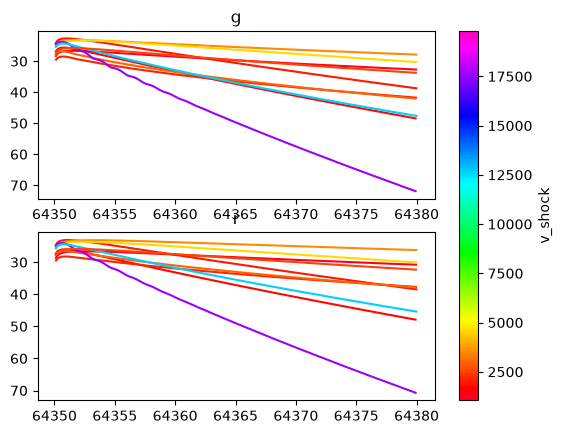

In [34]:
cmap = plt.colormaps['gist_rainbow']
which_param = 'v_shock' #"redshift" "v_shock" "m_env" "f_rho_m" "radius" "kappa" 
def modifier(arr):
    return arr
    # return np.log(arr)
lo, hi = modifier(min(graph_state['source'][which_param])), modifier(max(graph_state['source'][which_param]))
clims = (modifier(graph_state['source'][which_param]) - lo) / (hi - lo)

bands = 'gr'
fig, axs = plt.subplots(len(bands),1)

for b, band in enumerate(bands):
    ax = axs[b]
    for i in range(10):
        # plt.plot(lc['times'],lc['g'])
        lc = lcs['lightcurve'][i]
        ax.plot((np.array(lc['times'][:1000])*u.day), (np.array(lc[band][:1000])* u.nJy).to(u.ABmag, equivalencies=u.spectral()),
               c=cmap(clims[i]))
    ax.set_title(band)
    ax.invert_yaxis()
# plt.axvline(t0)
plt.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(lo, hi), cmap=cmap),
              ax=axs, label=which_param)
plt.show()

## defining metrics

![](https://content.cld.iop.org/journals/0004-637X/989/2/192/revision2/apjadea3af1_lr.jpg)

from [Crawford+25](doi.org/10.3847/1538-4357/adea3a)

![](https://content.cld.iop.org/journals/0004-637X/989/2/192/revision2/apjadea3at2_lr.gif)

Alex TODO:
- [ ] Identify time of peak
- [ ] Define pre-peak and post-peak observations up to tmax=15
- [ ] Count pre- and post- peak points above a threshold f

In [35]:
# split for testing purposes, will do array-wise next
def find_t_peak(lc, band):
    ipeak = np.argmax(lc[band])
    tpeak = lc['times'][ipeak]
    return ipeak, tpeak

def find_a1s(lcs, bands=('u', 'g', 'r', 'i', 'z', 'y')):
    a1s = {}
    for band in bands:
        a1 = []
        for i, lc in enumerate(lcs['lightcurve']):
            a1.append(find_t_peak(lc, band)[1] - t0)
        a1s['a1'+band] = a1
    return a1s

In [36]:
a1s = find_a1s(lcs)

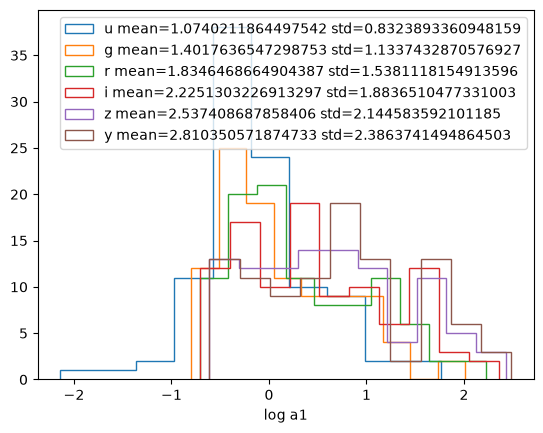

In [37]:
bands = 'ugrizy'
# fig, axs = plt.subplots(len(bands),1)
# which_param = 'kappa'# "redshift" "v_shock" "m_env" "f_rho_m" "radius" "kappa"
for b, band in enumerate(bands):
    # ax = axs[b]
    # plt.hist(np.log(a1s['a1'+band]), histtype='step', label=band+
             # ' mean=' +str(np.exp(np.mean(np.log(a1s['a1'+band]))))+
             # ' std='+str(np.exp(np.std(np.log(a1s['a1'+band])))))
    plt.hist(np.log(a1s['a1'+band]), histtype='step', label=band+
             ' mean=' +str(np.mean(a1s['a1'+band]))+
             ' std='+str(np.std(a1s['a1'+band])))
    # plt.scatter(graph_state['source'][which_param], np.log(a1s['a1'+band]), label=band, s=1)
#     for i in range(10):
#         # plt.plot(lc['times'],lc['g'])
#         lc = lcs['lightcurve'][i]
#         ax.plot((np.array(lc['times'][:1000])*u.day), (np.array(lc[band][:1000])* u.nJy).to(u.ABmag, equivalencies=u.spectral()),
#                c=cmap(clims[i]))
#     ax.set_title(band)
#     ax.invert_yaxis()
# # plt.axvline(t0)
# plt.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(lo, hi), cmap=cmap),
#               ax=axs, label=which_param)
plt.xlabel('log a1')
# plt.title(which_param)
plt.legend()
plt.show()

So people definitely did a lot of work to characterize these timescales a1 and a2 but the models don't look at all like the data so let's just go with counting observations within 5, 10, and 15 days.

In [38]:
def get_pre_peak(lc, band, time, t0=t0):
    tpre = lc['times'][lc['times'] < time + t0]
    # print(len(tpre)/len(lc[band]))
    return len(tpre)

def count_early(lcs, times=(5, 10, 15), bands=('u', 'g', 'r', 'i', 'z', 'y'), t0=t0):
    all_times = {}
    for time in times:
        counts = {}
        for band in bands:
            count = []
            for i, lc in enumerate(lcs['lightcurve']):
                # print(i)
                count.append(get_pre_peak(lc, band, time, t0=t0))
            counts[band] = count
        all_times[str(time)] = counts
    return all_times

In [56]:
# all_counts = count_early(lcs)

In [57]:
# plt.hist(all_counts['5']['u'])
# plt.show()

## now on realistic sims

In [41]:
source = RedbackWrapperModel(
    rb_model,
    parameters=parameters,  # Set ALL the redback model parameters
    ra=NumpyRandomFunc("uniform", low=0, high=360),  # Set other parameters
    dec=NumpyRandomFunc("uniform", low=-90, high=0),
    t0=NumpyRandomFunc("uniform", low=t_min, high=t_max),
    phase_bounds=(1e-3, 30),  # guess -- upper bound is days before primary supernova peak exceeds shock cooling peak (a2)
    node_label="source",
    time_extrapolation=(ConstantPadding(0.0), ConstantPadding(0.0)),
)
# state = source.sample_parameters(num_samples=1)

In [42]:
graph_state = source.sample_parameters(num_samples=1000)
passbands = PassbandGroup.from_preset("LSST") ;

{'a': array([1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 

In [43]:
df = simulate_lightcurves(model=source, graph_state=graph_state, num_samples=1000, survey_info=survey_info)

Simulating: 100%|███████████████████████████████████████████████| 1000/1000 [00:49<00:00, 20.26obj/s]


In [44]:
lcs = results_augment_lightcurves(df)

In [45]:
# lcs['lightcurve'][60]

In [46]:
# print(graph_state)

In [47]:
# i=3

# print(lcs['lightcurve'][i]['time_rel'][lcs['lightcurve'][i]['time_rel'] > 0])# & (lcs['lightcurve'][i]['time_rel'] < hi)]

# print(lcs['lightcurve'][i]['time_rel'][lcs['lightcurve'][i]['time_rel'] < hi])

In [48]:
def get_pre_peak(lc, band, time, t0=t0):
    tpre = lc['times'][lc['times'] < time + t0]
    # print(len(tpre)/len(lc[band]))
    return len(tpre)

# could also do with 0 < time_rel < time
def count_early(lcs, times=(5, 10, 15), bands=('u', 'g', 'r', 'i', 'z', 'y'), t0=t0):
    all_times = []
    with_filt = []
    hi = max(times)
    for i, lc in enumerate(lcs['lightcurve']):
        subset = lcs['lightcurve'][i][(lcs['lightcurve'][i]['time_rel'] > 0) & (lcs['lightcurve'][i]['time_rel'] < hi)]
        counts = []
        deets = []
        for time in times:
            counts.append(len(subset[subset['time_rel'] < time]))
            deets.append(subset['filter'][subset['time_rel'] < time])
            # for band in bands:
            #    count.append(get_pre_peak(lc, band, time, t0=t0))
            # counts[band] = count
        all_times.append(counts), with_filt.append(deets)
    return all_times, with_filt

In [49]:
counts, deets = count_early(lcs)
res = np.array(counts)

In [50]:
res

array([[2, 2, 4],
       [0, 0, 0],
       [0, 0, 0],
       ...,
       [0, 0, 0],
       [2, 4, 4],
       [4, 6, 6]], shape=(1000, 3))

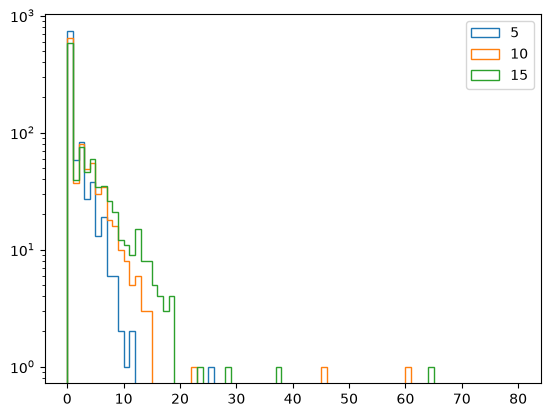

In [51]:
times=(5, 10, 15)
for i in range(len(times)):
    plt.hist(res[:,i], bins=range(np.max(res)), label=times[i], histtype='step')
plt.legend()
plt.semilogy()
plt.show()

In [52]:
deets

[[287    r
  288    g
  Name: filter, dtype: str,
  287    r
  288    g
  Name: filter, dtype: str,
  287    r
  288    g
  289    g
  290    u
  Name: filter, dtype: str],
 [Series([], Name: filter, dtype: str),
  Series([], Name: filter, dtype: str),
  Series([], Name: filter, dtype: str)],
 [Series([], Name: filter, dtype: str),
  Series([], Name: filter, dtype: str),
  Series([], Name: filter, dtype: str)],
 [Series([], Name: filter, dtype: str),
  Series([], Name: filter, dtype: str),
  Series([], Name: filter, dtype: str)],
 [460    y
  461    y
  462    y
  463    y
  464    z
  465    z
  466    i
  467    i
  Name: filter, dtype: str,
  460    y
  461    y
  462    y
  463    y
  464    z
  465    z
  466    i
  467    i
  468    z
  469    z
  470    y
  471    y
  472    z
  473    i
  Name: filter, dtype: str,
  460    y
  461    y
  462    y
  463    y
  464    z
  465    z
  466    i
  467    i
  468    z
  469    z
  470    y
  471    y
  472    z
  473    i
  Name: filt

In [53]:
# get_pre_peak(lc, 'r')

In [54]:
# def get_post_peak(lc, band, fthresh=0):
    

In [55]:
# a1 = {'g': sps.normal(7.2, 3.3),
#       'r': sps.normal(7.7, 3.1),
#       'i': sps.normal()}